## Test training


In [1]:
%load_ext autoreload
%autoreload 1

import os
os.environ["QUANTDATA_ROOT"] = "/mnt/c/Users/Public/quantdata"

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.sampler
%aimport quantdata.torch
%aimport quantdata.torch.ffw
%aimport quantdata.dysanos
%aimport quantdata.dysanos.data
%aimport quantdata.dysanos.data.simple

from cdxcore.verbose import Context
verbose = Context("all")
with verbose.write_t("Importing torch...", end='') as tme:   
    import torch
    verbose.write(f"done; this took {tme}.", head=False)

from quantdata.dysanos.data.simple import SimpleSampler, SimpleConfig, SamplingConfig, ExpiryFilter, RawDayFilter, SampleDaysConfig, DateRange, PoolConfig
from cdxcore.verbose import Context
from IPython.display import display
from datetime import date

def test():
    simple_config = SimpleConfig(
            tickers = ['SPX','NDX','RUT'],
            date_range = DateRange(start=date(2025, 1, 1), end=date(2025, 7, 1)),
            raw_day_filter = RawDayFilter(),
            expiry_filter = ExpiryFilter(),
            sample_days_config = SampleDaysConfig(),
            sampling_config = SamplingConfig(num_samples=20)
    )
    pool_config = PoolConfig(num_workers=4, threading=True) # no parallel processing for testing
    verbose = Context.all
    refresh_cache = False

    sampler = SimpleSampler(simple_config=simple_config, pool_config=pool_config, refresh_cache=refresh_cache, verbose=verbose)
    return sampler

sampler = test()
print("/done")

00: Importing torch...done; this took 0.00453ms.
00: Generating samples for 3 tickers NDX, RUT and SPX with from 2025-01-01 to 2025-07-01... done; this took 0.31s.
00: Found the following number of samples per ticker: SPX: 122, RUT: 122 and NDX: 122.
00: Found date range 2025-01-02 to 2025-07-01 with 122 total dates. First validation date for 25 steps per sample is 2025-05-06.
00: Using up to 1000 options per date.
01:   Ticker SPX: using 12 training samples (accross 83 training dates), and 3 validation samples (accross 39 validation dates).
01:   Ticker RUT: using 12 training samples (accross 83 training dates), and 3 validation samples (accross 39 validation dates).
01:   Ticker NDX: using 12 training samples (accross 83 training dates), and 3 validation samples (accross 39 validation dates).
00: Created 36 training samples and 9 validation samples based on the date split at 2025-05-06. That implies 20% of all samples are validation samples.
/done


## Training a simple MLP

/model created.
01:   Launching AEC training for 100 epochs over 36 training and 9 validation samples, using a mini bastch size of 16 for 4 batches per epoch, and a batch size of 64 for valuation.
01:   Training epoch 1/100 error avg trn 1.089e+05; val 0.0007631/0.0006686 [1.1s 0.17s 0.092s]. LR: 1.00e-02, excess: 0.02918/0.02529. ETA: 2:17.


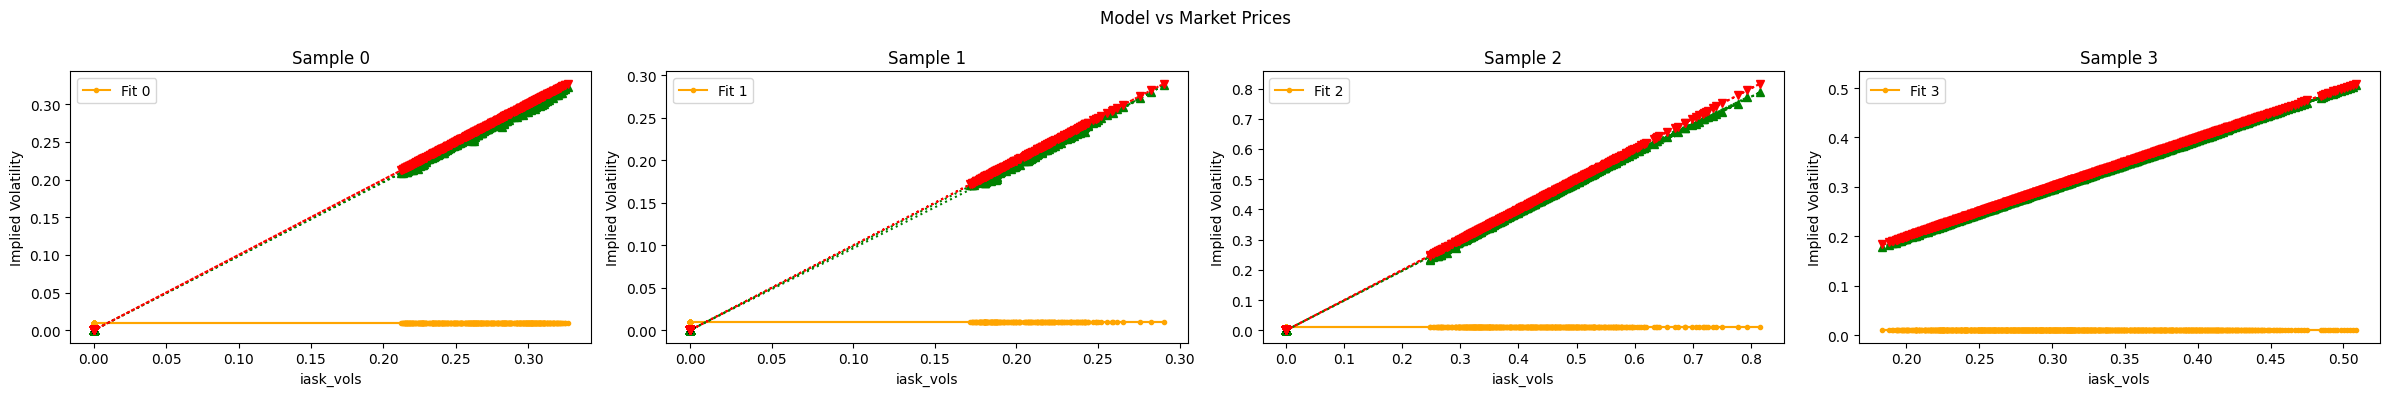

01:   Training epoch 2/100 error avg trn 0.0007669; val 0.0007631/0.0006686 [0.97s 0.17s 0.093s]. LR: 1.00e-02, excess: 0.02918/0.02529. ETA: 5:05.
01:   Training epoch 3/100 error avg trn 0.0007805; val 0.0007631/0.0006686 [0.94s 0.17s 0.093s]. LR: 1.00e-02, excess: 0.02918/0.02529. ETA: 7:43.
01:   Training epoch 4/100 error avg trn 0.0007278; val 0.0007631/0.0006686 [0.92s 0.17s 0.093s]. LR: 1.00e-02, excess: 0.02918/0.02529. ETA: 10:15.
01:   Training epoch 5/100 error avg trn 0.0007887; val 0.0007631/0.0006686 [0.91s 0.17s 0.094s]. LR: 1.00e-02, excess: 0.02918/0.02529. ETA: 12:46.
01:   Training epoch 6/100 error avg trn 0.0007296; val 0.0007631/0.0006686 [0.9s 0.17s 0.094s]. LR: 1.00e-02, excess: 0.02918/0.02529. ETA: 15:10.
01:   Training epoch 7/100 error avg trn 0.0007786; val 0.0007631/0.0006686 [0.9s 0.17s 0.094s]. LR: 1.00e-02, excess: 0.02918/0.02529. ETA: 17:30.
01:   Training epoch 8/100 error avg trn 0.0007244; val 0.0007631/0.0006686 [0.89s 0.17s 0.094s]. LR: 1.00e-02

KeyboardInterrupt: 

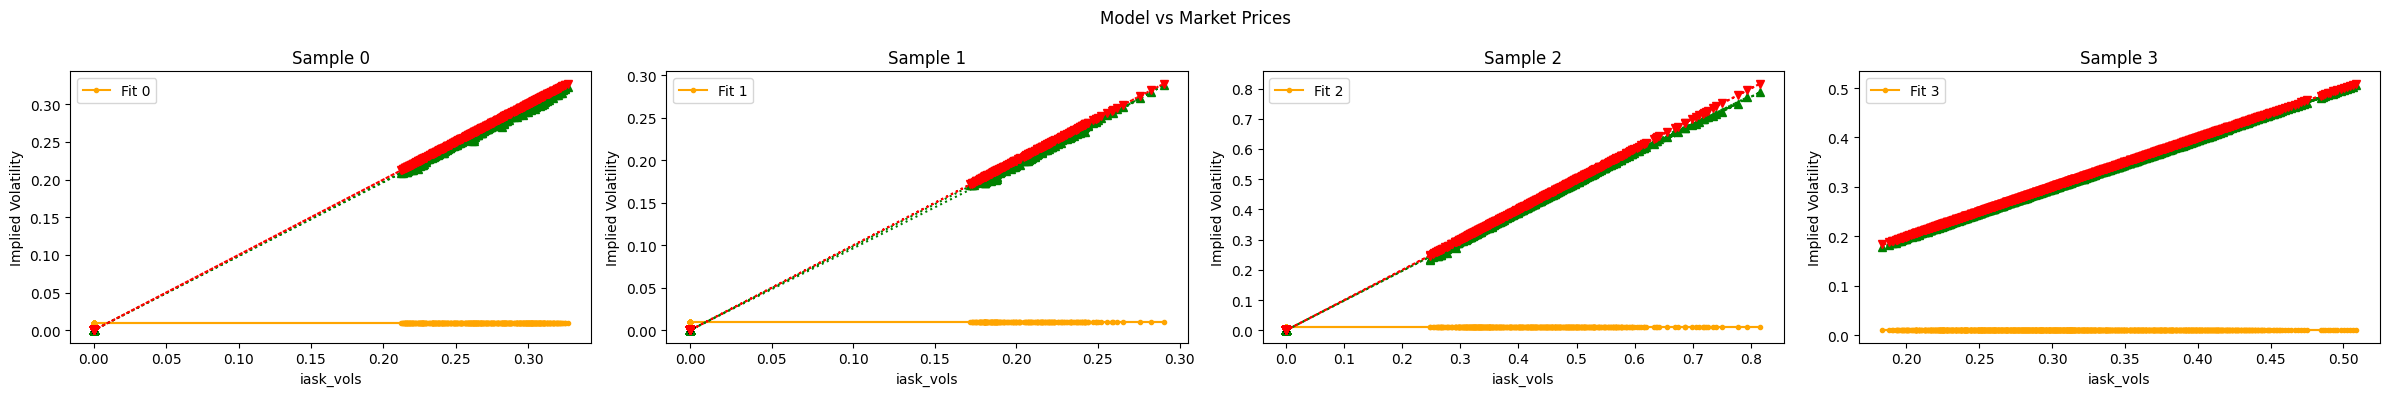

In [ ]:
# reloader

%aimport quantdata.torch
%aimport quantdata.torch.sampler
%aimport quantdata.utils.backbone
%aimport quantdata.torch.bbtorch
%aimport quantdata.torch.ffw

from wandb.util import np

from quantdata.torch import get, pop
from quantdata.torch.sampler import BlockSampler
from quantdata.torch.ffw import FastForward, BaseEnvironment, BaseModel, dataclass, tnn
from quantdata.torch.bbtorch import BackboneTorch
from dataclasses import dataclass, field
from cdxcore.err import verify_inp
from enum import IntEnum
from collections.abc import Mapping

class AEC(BaseModel):
    """ Environment for training Spock """

    @dataclass(frozen=True)
    class Config:
        encode_what         : str = "vol"
        num_state           : int = 32                                   #: Hidden state dimension
        num_compress        : int = 128                                  #: Internal state compression dimension for deep set
        encoder_set_config  : FastForward.Config = FastForward.Config()  #: Configuration for the encoder
        encoder_fix_config  : FastForward.Config = FastForward.Config()  #: Configuration for the encoder
        decoder_config      : FastForward.Config = FastForward.Config()  #: Configuration for the encoder

        min_pure_spread     : float = 1E-5
        mid_fit_weight      : float = 1E-3

        def __post_init__(self):
            verify_inp( self.num_state > 0, lambda : f"'num_state' must be positive, but found {self.num_state}" )
            verify_inp( self.num_compress > 0, lambda : f"'num_compress' must be positive, but found {self.num_compress}" )
            verify_inp( self.min_pure_spread > 0., lambda : f"'min_pure_spread' must be positive, but found {self.min_pure_spread:.4g}" )
            verify_inp( 0. <= self.mid_fit_weight <= 1., lambda : f"'mid_fit_weight' must be in [0,1], but found {self.mid_fit_weight:.4g}" )

            if self.encode_what not in {"vol", "price"}:
                raise ValueError(f"Invalid value for encode_what: {self.encode_what}. Expected 'vol' or 'price'.")           

    class ReturnWhat(IntEnum):
        LOSS_WEIGHT = 0  #: return float ``loss`` (with gradient) and float ``weight`` (without gradient) for training. 
        VALUATION = 1    #: return ``loss``, ``weight`` and a dictionary of additional float metrics.
        PATHWISE = 2     #: return pathwise metrics

    X_FEATURES = [
        'call_ask',   # first element must have full dimension (B,S,O) to determine the number of options O
        'call_bid',
        'spot_ret',
        #'is_american',
        #'is_am',
        'strike', 
        'df',
        'tte_y',
        'fwd',
        'nms',
        'ask_vol',
        'bid_vol',
        'log_volume',
        'log_open_interest',
        'ask_pure_price',
        'bid_pure_price',
        'ask_pure_delta',
        'bid_pure_delta',
        'ask_pure_gamma',
        'bid_pure_gamma',
        'bid_pure_vega',
        'ask_pure_vega',
        'bid_pure_theta',
        'ask_pure_theta',
        'ask_pure_dk',
        'bid_pure_dk'
    ]

    CHARACTERISTICS = [
        'tte_y',
        'nms',
        'strike'
    ]

    def __init__(self, env         : BaseEnvironment, *,
                       shapes      : dict[str, tuple], # shapes of the input data fields, used for verification and to determine the number of features
                       num_steps   : int, # expected number of steps
                       max_options : int, # expected maximum number of options per step
                       config      : Config = Config()
                 ):
        """ Initialize model """
        super().__init__(env=env)

        if set(shapes) != set(SimpleSampler.FEATURES):
            superfluous = set(shapes) - set(SimpleSampler.FEATURES)
            missing = set(SimpleSampler.FEATURES) - set(shapes)
            msg = "Data Input mismatch:"
            if superfluous:
                msg += f" Superfluous fields: {superfluous}."
            if missing:
                msg += f" Missing fields: {missing}."   
            raise ValueError(msg)
        
        if set(self.X_FEATURES) > set(SimpleSampler.FEATURES):
            raise RuntimeError(f"Model {self.__class__.__name__} requires features that are not provided by the data sampler: {sorted(set(self.X_FEATURES) - set(SimpleSampler.FEATURES))}.")
        if set(self.CHARACTERISTICS) > set(SimpleSampler.FEATURES):
            raise RuntimeError(f"Model {self.__class__.__name__} requires characteristics that are not provided by the data sampler: {sorted(set(self.CHARACTERISTICS) - set(SimpleSampler.FEATURES))}.")

        self.config        = config
        self.num_features  = len(self.X_FEATURES)
        self.num_characteristics = len(self.CHARACTERISTICS)
        self.num_steps     = num_steps
        self.max_options   = max_options
        self.bb            = BackboneTorch(env) # for black scholes pricer

        self.encode_set    = FastForward( env, num_input=self.num_features, num_output=self.config.num_compress, config=self.config.encoder_set_config )
        self.encode_fix    = FastForward( env, num_input=self.config.num_compress, num_output=self.config.num_state, config=self.config.encoder_fix_config )
        self.decode        = FastForward( env, num_input=self.config.num_state+self.num_characteristics, num_output=0, config=self.config.decoder_config )
        self.softplus      = torch.nn.Softplus()
    
    def forward(self, data          : dict, 
                      training      : bool = False,
                      return_what   : ReturnWhat = ReturnWhat.LOSS_WEIGHT ) -> tuple[torch.Tensor, torch.Tensor]|tuple[torch.Tensor, torch.Tensor, dict[str, torch.Tensor]]:
        """
        Forward pass

        Parameters
        ----------
        data : dict
            Dictionary of data.

        training : bool, default ``False``
            Whether the model is in training mode.
            If ``True``, the model will return ``(loss, weight)`` for backpropagation where only ``loss`` has a gradient.
        
            return_prices : bool, default ``False``
            Whether to return prices.

        """
        assert set(data) == set(SimpleSampler.FEATURES), f"Data fields wrong: superflous: {sorted(set(data) - set(SimpleSampler.FEATURES))}, missing: {sorted(set(SimpleSampler.FEATURES) - set(data))}"
        assert not training or return_what == self.ReturnWhat.LOSS_WEIGHT, f"During training, 'return_what' must be ReturnWhat.LOSS_WEIGHT not {return_what}"

        data     = dict(data)
        mask     = pop(data,"is_valid", shape=3, dtype=torch.bool) # (B,S,O)
        B, S, O  = mask.shape
        assert S == self.num_steps, f"Expected mask to have {self.num_steps} steps as the second dimension, but got {S}"
        assert O == self.max_options, f"Expected mask to have {self.max_options} options as the third dimension, but got {O}"
        self.verify( lambda : torch.any(mask), "Batch contains no valid masked samples.")

        # encode
        # ------

        def encoder():
            features = [ data[f] for f in self.X_FEATURES ] # list of (B,S,O) tensors
            encode   = self.encode_set( features, mask = mask )
            assert encode.shape == (B, S, O, self.config.num_compress), f"Expected encoded representation to have shape {(B, S, O, self.config.num_compress)}, but found {encode.shape}"        
            encode   = torch.sum( encode, dim=2 ) / torch.sum( mask[...,None], dim=2 )# (B,S,self.config.num_compress) - average over options, weighted by mask
            encode   = torch.tanh(encode) # (B,S,self.config.num_state) - nonlinearity
            encode   = self.encode_fix( encode ) # (B,S,self.config.num_state)
            assert encode.shape == (B, S, self.config.num_state), f"Expected encoded representation after fix to have shape {(B, S, self.config.num_state)}, but found {encode.shape}"
            encode   = torch.tanh(encode) # (B,S,self.config.num_state) - nonlinearity
            return encode

        state = encoder()
        self.verify( lambda: torch.isfinite(state).all(), lambda: f"Encoded state representation contains non-finite values; found {torch.min(state[mask]).item():.4f}" )

        # project using current market
        # ----------------------------

        def decoder():
            characteristics = [ data[f] for f in self.CHARACTERISTICS ] +\
                              [ state[:,:,None,i] for i in range(state.shape[-1]) ] 
            
            for c in characteristics:
                assert len(c.shape) == 3 and c.shape[0] == B and c.shape[1] == S, f"Expected characteristic/state tensors to have shape (B,S,...) but found {c.shape}"

            decoded        = self.decode( characteristics, mask = mask ) # (B,S,O)
            assert decoded.shape == (B, S, O), f"Expected decoded representation to have shape {(B, S, O)}, but got {decoded.shape}"
            return decoded

        decoded = decoder()
        self.verify( lambda: torch.isfinite(decoded).all(), lambda: f"Decoded representation contains non-finite values; found {torch.min(decoded[mask]).item():.4f}" )

        # Compute price
        # -------------

        pure_strike = data['strike'] / torch.where( mask, data['fwd'], 1. )
        sqrtT       = data['tte_y'].sqrt() 
        pure_ask    = data['ask_pure_price']
        pure_bid    = data['bid_pure_price']
        pure_mid    = 0.5*(pure_ask + pure_bid)
        pure_spread = torch.clip( pure_ask - pure_bid, min=self.config.min_pure_spread )

        if self.config.encode_what == "vol":
            fit_vol   = self.softplus(decoded) # ensure positive output for volatility prediction
            fit_price = self.bb.bs_price( strikes=pure_strike, sqrtVars=fit_vol*sqrtT, mask=mask, high_precision=False, debug_verify_bounds=False )
    
        else:
            assert self.config.encode_what == "price", f"Invalid value for 'encode_what': {self.config.encode_what}"
            fit_vol    = None
            fit_price  = self.softplus(decoded) # ensure positive output for price prediction

        self.verify( lambda: torch.isfinite(fit_price).all(), lambda: f"Mid price must be positive for valid samples; found {torch.min(fit_price[mask]).item():.4f}" )

        # loss function
        # -------------

        weights      = torch.where( mask, 1./torch.where(mask, pure_spread, 1.), 0. ) # (B,S,O) weight inversely proportional to spread, but zero if mask is not valid
        excess       = torch.relu( fit_price - pure_ask ) + torch.relu( pure_bid - fit_price )
        loss         = weights * ( (1.-self.config.mid_fit_weight ) * excess + self.config.mid_fit_weight * ( fit_price - pure_mid )**2 )
    
        loss         = torch.sum(loss)
        with torch.no_grad():
            weight  = torch.sum(weights)

        if training or return_what == self.ReturnWhat.LOSS_WEIGHT:
            return loss, weight
        if return_what == self.ReturnWhat.VALUATION:
            with torch.no_grad():
                excess  = torch.sum(torch.where(mask,excess,0.)) if not training else None
                count   = torch.sum(mask) if not training else None
            return loss, weight, dict(excess=excess, count=count)
        
        assert return_what == self.ReturnWhat.PATHWISE, f"Invalid value for 'return_what': {return_what}"
        return dict(fit_price=torch.where( mask, fit_price, 0.),
                    fit_vol=torch.where( mask, fit_vol, 0.) if fit_vol is not None else None
                )


env   = BaseEnvironment(device="cuda", debug=True)

aec_config = AEC.Config(
    num_state = 32,
    num_compress = 128   ,
    encode_what = "price",
    mid_fit_weight = 1.,
    encoder_set_config = FastForward.Config(
        num_depth = 2,
        num_width = 32,
        activation = 'Softplus',
    ),
    encoder_fix_config = FastForward.Config(
        num_depth = 2,
        num_width = 64,
        activation = 'Softplus',
    ),
    decoder_config = FastForward.Config(
        num_depth = 2,
        num_width = 32,
        activation = 'Softplus',
    )
)

model = AEC(env=env, 
            shapes=sampler.shapes(), 
            num_steps=sampler.num_steps,
            max_options=sampler.max_options,
            config=aec_config )

print("/model created.")

from cdxcore.util import TrackTime, fmt_seconds, fmt_list

@dataclass(frozen=True)
class TrainConfig:
    trn_batch_size  : int = 16
    val_batch_size  : int = 64
    batch_per_epoch : int = 4

    # clipping
    max_grad_norm   : float|None = 1.

    # optimizer
    lr_init         : float = 0.01
    lr_final        : float = 1E-5
    lr_init_steps   : int = 10
    lr_decay_steps  : int = 100 

    def learning_rate( self, init_epoch ) -> callable:
        def learning_rate( step ):
            """ Compute learning rate for a given epoch, using exponential decay from lr_init to lr_final over lr_decay_steps """
            epoch = step + init_epoch            
            if epoch <= self.lr_init_steps:
                return 1.
            elif epoch >= self.lr_init_steps + self.lr_decay_steps:
                return self.lr_final/self.lr_init
            else:
                decay_factor = (self.lr_final / self.lr_init) ** ((epoch - self.lr_init_steps) / self.lr_decay_steps)
                assert 0. < decay_factor <= 1., f"Internal error: decay_factor should be in (0,1], but got {decay_factor} for epoch {epoch}"
                return decay_factor
        return learning_rate

from cdxcore.bs import bs
from cdxcore.dynaplot import figure, colors_base, store, m_o_m
from quantdata.biz_calendar import DAYS_PER_YEAR
import numpy as nnp

class Visualizer(object):

    @dataclass(frozen=True)
    class Config:
        seed    : int = 1234
        num_viz : int = 4
        use_trn : bool = True

    def __init__( self, sampler : SimpleSampler, config : Config = Config() ):
        self.sampler = sampler
        self.config  = config
        self.rng     = nnp.random.default_rng(config.seed)

        self.sample_ids  = sorted( self.rng.choice( sampler.trn_samples_ids if config.use_trn else sampler.vld_samples_ids, size=config.num_viz, replace=False ) )

        self.fig     = None
        self.axs     = None
        self.store   = store()

    def update( self, model : AEC, epoch : int ):
        """ Update visualizer with new model and epoch number """
        model.eval()
        with torch.no_grad():
            batch         = self.sampler.generate_batch( self.sample_ids, device = model._env.device )
            is_valid      = batch['is_valid'].detach().cpu().numpy()
            num_opts      = is_valid.shape[-1]
            is_valid      = is_valid[:,-1,:]
            assert is_valid.shape[0] == self.config.num_viz, f"Expected number of valid samples to match number of visualizations {self.config.num_viz}, but found {is_valid.shape[0]}"

            bid_vols      = batch['bid_vol'][:,-1,:].detach().cpu().numpy()
            ask_vols      = batch['ask_vol'][:,-1,:].detach().cpu().numpy()
            nms           = batch['nms'][:,-1,:].detach().cpu().numpy()
            tte_y         = batch['tte_y'][:,-1,:].detach().cpu().numpy()
            fwd           = batch['fwd'][:,-1,:].detach().cpu().numpy()
            strike        = batch['strike'][:,-1,:].detach().cpu().numpy()
            pure_strike   = strike / np.where( is_valid, fwd, 1. ) # set pure_strike to strike for invalid samples to prevent NaNs in visualization
            sqrtT         = np.sqrt(tte_y)

            pathwise      = model( batch, training=False, return_what=model.ReturnWhat.PATHWISE )
            fit_price     = pathwise['fit_price'][:,-1,:].detach().cpu().numpy()
            fit_vols      = pathwise['fit_vol'][:,-1,:].detach().cpu().numpy() if pathwise['fit_vol'] is not None else None

            num_plots     = fit_price.shape[0]
            is_first      = self.fig is None
            if is_first:
                self.fig = figure( title="Model vs Market Prices", col_size=6, row_size=4, columns=4 )
                self.axs = [ self.fig.add_subplot(f"Sample {i}") for i in range(num_plots) ]

            self.store.clear()

            # Per expiry
            for ip, ax in enumerate(self.axs):
                ivld       = is_valid[ip,:]
                inms       = nms[ip,:][ivld]
                ixs        = np.argsort(inms)
                inms       = inms[ixs]
                ipure_k    = pure_strike[ip,:][ixs]
                isqrtT     = sqrtT[ip,:][ixs]
                ibid_vols  = bid_vols[ip,:][ixs]
                iask_vols  = ask_vols[ip,:][ixs]

                if not fit_vols is None:
                    ifit_vols  = fit_vols[ip,:][ixs]
                else:
                    ifit_price = fit_price[ip,:][ixs]
                    ifit_vols  = bs.implied( ipure_k, ifit_price, sqrtT=isqrtT )

                self.store += ax.plot( iask_vols, ifit_vols, ".-", color="orange", label=f"Fit {ip}" )
                self.store += ax.plot( iask_vols, ibid_vols, "^:", color="green")
                self.store += ax.plot( iask_vols, iask_vols, "v:", color="red")

                ax.set_ylim( *m_o_m(ifit_vols, ibid_vols, iask_vols ))

                if is_first:
                    ax.set_xlabel("iask_vols")
                    ax.set_ylabel("Implied Volatility")
                    ax.legend(loc="upper left")
            self.fig.render()

def train( env     : BaseEnvironment,
           epochs  : int,
           model   : AEC,
           sampler : BlockSampler,
           config  : TrainConfig,
           verbose : Context = Context.all ):

    init_epoch = 0 # TODO: load state

    verbose.write(lambda : f"Launching {model.__class__.__name__} training for {epochs} epochs over {sampler.num_trn_samples} training and {sampler.num_vld_samples} validation samples, using a mini bastch size of "+\
                           f"{config.trn_batch_size} for {config.batch_per_epoch} batches per epoch, and a batch size of {config.val_batch_size} for valuation.")
    rndg = torch.Generator(device="cpu")

    optimizer = torch.optim.Adam(model.parameters(), lr=config.lr_init)
    scheduler = torch.optim.lr_scheduler.LambdaLR( optimizer, lr_lambda=config.learning_rate(init_epoch) )

    tracker    = TrackTime()
    visualizer = Visualizer(sampler, config = Visualizer.Config(num_viz=4, use_trn=True) )

    # training
    # --------

    for epoch in range(init_epoch+1, epochs+1):

        assert all(torch.isfinite(p).all().item() for p in model.parameters()), "Model parameters contain non-finite values before training step"

        with tracker("training"):
            def train():
                tme    = verbose.timer()
                loss   = 0.
                weight = 0.
                model.train()
                for imini in range(config.batch_per_epoch):
                    lr   = scheduler.get_last_lr()[0] if scheduler is not None else config.lr_init
                    verbose.write(lambda : f"\rTraining epoch {epoch}/{epochs} mini batch {imini+1}/{config.batch_per_epoch} with learning rate {lr:.2e}: so far this took {tme}...", end='')

                    batch = sampler( rndg, trn=True, batch_size=config.trn_batch_size, device=env.device, return_batch_indices=False )
                    assert batch['is_valid'].any().item(), "Sampled batch contains no valid samples. Check the sampler and the data."

                    optimizer.zero_grad(set_to_none=True)

                    assert all(torch.isfinite(p).all().item() for p in model.parameters()), f"Model parameters contain non-finite values before model call {epoch} {imini}"
                    ls, wg = model( batch, training=True )
                    mini_loss = ls / wg
                    assert torch.isfinite(mini_loss).all(), f"Internal error: mini_loss infinite"

                    mini_loss.backward()
                    if config.max_grad_norm is not None:
                        torch.nn.utils.clip_grad_norm_(model.parameters(), config.max_grad_norm)
                    optimizer.step()
                    assert all(torch.isfinite(p).all().item() for p in model.parameters()), f"Model parameters contain non-finite values after optimizer step {epoch} {imini}"

                    loss    += ls.detach().item()
                    weight  += wg.detach().item()
                scheduler.step() if not scheduler is None else None  # decay LR by 5%
                return loss / weight

            trn_loss = train()

        lr = scheduler.get_last_lr()[0] if scheduler is not None else config.lr_init
        str_tme_trn = f"{tracker['training'].fmt_average_lap_seconds()}"
        verbose.write(lambda : f"\rTraining epoch {epoch}/{epochs} error avg trn {trn_loss:.4g} [{str_tme_trn}] learning rate {lr:.2e}", end='')

        with torch.no_grad():
            def value( trn ):
                loss    = 0.
                weight  = 0.
                metrics = {}

                for batch in sampler.all( trn=trn, batch_size=config.val_batch_size, device=env.device ):
                    ls, wg, lm = model( batch, training=False, return_what=model.ReturnWhat.VALUATION )
                    ls      = ls.detach().item()
                    wg      = wg.detach().item()   
                    lm      = { k: v.detach().item() for k,v in lm.items() }
                    assert nnp.isfinite(ls) and nnp.isfinite(wg) and wg > 0, f"Internal error: {ls} {wg}"
                    loss    += ls
                    weight  += wg
                    metrics = { k: metrics.get(k, 0.) + v for k,v in lm.items() }

                count   = metrics.pop("count")
                assert count > 0, f"Internal error: no valid samples"
                metrics = { k: v/count for k,v in metrics.items() }
                return loss / weight, metrics
            
            with tracker("val_trn"):
                trn_val_loss, trn_metrics = value(trn=True)
            with tracker("val_vld"):
                vld_val_loss, vld_metrics = value(trn=False)    
            
        str_tme_val_trn = f"{tracker['val_trn'].fmt_average_lap_seconds()}"
        str_tme_val_vld = f"{tracker['val_vld'].fmt_average_lap_seconds()}"   
        str_estimated   = fmt_seconds( tracker.current_lap_seconds * (epochs - epoch) )

        str_metrics = f"LR: {lr:.2e}, "
        for k in trn_metrics:
            trn_v = trn_metrics[k]
            vld_v = vld_metrics[k]
            str_metrics += f"{k}: {trn_v:.4g}/{vld_v:.4g}, "
        str_metrics = str_metrics[:-2] + "."
        verbose.write(lambda : f"\rTraining epoch {epoch}/{epochs} error avg trn {trn_loss:.4g}; val {trn_val_loss:.4g}/{vld_val_loss:.4g} "+\
                               f"[{str_tme_trn} {str_tme_val_trn} {str_tme_val_vld}]. {str_metrics} ETA: {str_estimated}.")
        
        visualizer.update(model, epoch)

    return model

train( env, epochs=100, model=model, sampler=sampler, config=TrainConfig(), verbose=verbose(1) )
